# Daily disease-post forecasting: historical prototype

Forecast **AURI, pneumonia (PN), tuberculosis (TB), and COVID** signals in the sampled HealthPH+ social-media corpus, seven days ahead. This notebook audits time coverage, attaches frozen XLM-RoBERTa predictions to durable post identities, and compares four simple forecasting baselines.

**Interpretation:** these are counts of model-labeled posts in a retrospectively collected sample. Uneven keyword searches, collection limits, and source changes affect counts. Missing posting dates do not establish zero public activity. The classifier was trained in October 2026 with random annotation splits and no chronological training cutoff; these results do not measure prospective outbreak prediction or clinical cases.

Run all cells with the project `.venv` kernel, from the repository root or `notebooks/`. The complete local October 22 XLM-RoBERTa bundle is required. No training, model download, or running HTTP service is needed. Successful prediction batches are cached so an interrupted labeling run can resume.

## 1. Configuration

The default 91-day window is **September 1–November 30, 2025**, in Asia/Manila time. It contains 5,892 sampled posts before text-quality exclusions; 24 exceed the predictor's input limit. All sources are pooled, with their changing composition shown in the audit.

Use 56 initial history days, three weekly validation origins, and two weekly test origins. Changing dates requires a contiguous window with exactly the configured number of days. Prediction failures stop execution; they never become negative disease labels.

In [1]:
import hashlib
import json
import os
import platform
import sys
import time
import uuid
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / 'healthph_plus').is_dir() and (p / 'notebooks').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Run from the repository root or notebooks/ with the project kernel.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from healthph_plus.forecast_data import LABELS, prepare_posts, label_posts, aggregate_daily
from healthph_plus.forecasting import BASELINES, evaluate_baselines
from healthph_plus.forecast_reporting import export_forecast_report
from healthph_plus.model_reporting import save_table, save_figure

DATA_PATH = ROOT / 'data/processed/merged_data.csv'
BUNDLE_DIR = ROOT / 'xlmr-disease-detection-service/model'
EXPECTED_MODEL_RUN = 'full_20261022T064326Z_fa1cd053'
CACHE_PATH = ROOT / 'artifacts/forecasting/prediction_cache.json'
TIMEZONE = 'Asia/Manila'
START_DATE = '2025-09-01'
END_DATE = '2025-11-30'
INITIAL_TRAIN_DAYS = 56
VALIDATION_FOLDS = 3
TEST_FOLDS = 2
HORIZON = 7
BATCH_SIZE = 32
CPU_THREADS = min(4, os.cpu_count() or 1)

expected_days = INITIAL_TRAIN_DAYS + (VALIDATION_FOLDS + TEST_FOLDS) * HORIZON
if len(pd.date_range(START_DATE, END_DATE, freq='D')) != expected_days:
    raise ValueError(f'The configured evaluation requires exactly {expected_days} calendar days.')
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Missing processed corpus: {DATA_PATH}')

RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
REPORT_DIR = ROOT / 'reports/forecasting' / RUN_ID
REPORT_DIR.mkdir(parents=True, exist_ok=False)
CONFIG = {
    'run_id': RUN_ID, 'created_at_utc': datetime.now(timezone.utc).isoformat(), 'status': 'running',
    'dataset_path': str(DATA_PATH), 'model_bundle': str(BUNDLE_DIR),
    'expected_model_run': EXPECTED_MODEL_RUN, 'cache_path': str(CACHE_PATH),
    'timezone': TIMEZONE, 'start_date': START_DATE, 'end_date': END_DATE,
    'initial_train_days': INITIAL_TRAIN_DAYS, 'validation_folds': VALIDATION_FOLDS,
    'test_folds': TEST_FOLDS, 'horizon': HORIZON, 'batch_size': BATCH_SIZE,
    'cpu_threads': CPU_THREADS, 'labels': list(LABELS), 'baselines': list(BASELINES),
    'selection': 'validation MAE, then RMSE, then listed baseline order',
    'target': 'retrospective frozen-classifier disease counts in the sampled corpus',
    'classifier_temporal_limitation': 'Trained October 2026; random annotation splits; no chronological cutoff.',
    'python': platform.python_version(),
    'packages': {name: version(name) for name in ('pandas', 'numpy', 'torch', 'transformers', 'matplotlib')},
}

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False,
                                    allow_nan=False, default=str) + '\n', encoding='utf-8')

write_json(REPORT_DIR / 'run_config.json', CONFIG)
print('Report directory:', REPORT_DIR)
print('Window:', START_DATE, 'through', END_DATE, '| timezone:', TIMEZONE)


Report directory: /Users/gelo-p1/Documents/GitHub/HealthPH-Plus/reports/forecasting/20261028T062743Z_7ad49ebb
Window: 2025-09-01 through 2025-11-30 | timezone: Asia/Manila


## 2. Audit the timestamped corpus

Use the original `date_posted`, not the preprocessing or collection timestamp. Durable identities are `(source, external_post_id)`; regenerated internal UUIDs are not join keys. Identical duplicate identities are counted once, conflicting identities raise an error, and invalid inputs are exported with reasons without raw post text.

The full-corpus coverage plot shows sampled presence only. An empty month can reflect collection coverage; it is not a claim about disease activity.

{
  "input_posts": 53273,
  "selected_input_posts": 5892,
  "duplicate_posts": 0,
  "selected_excluded_posts": 24,
  "eligible_posts": 5868
}
Selected-window exclusions: {'text_too_long': 24}
Full-corpus exclusions (including outside-window posts): {'outside_window': 46964, 'text_too_long': 441}


,row_number,source,external_post_id,reason
0,307,twitter,1925703159839621432,outside_window
1,308,twitter,1925703128038400207,outside_window
2,309,twitter,1925702927139623105,outside_window
3,310,twitter,1925702805932662912,outside_window
4,311,twitter,1925702679092686979,outside_window
5,312,twitter,1925702643902451924,outside_window
6,313,twitter,1925702577116647803,outside_window
7,314,twitter,1925702549392302215,outside_window
8,315,twitter,1925702425442168977,outside_window
9,316,twitter,1914831426010112461,outside_window


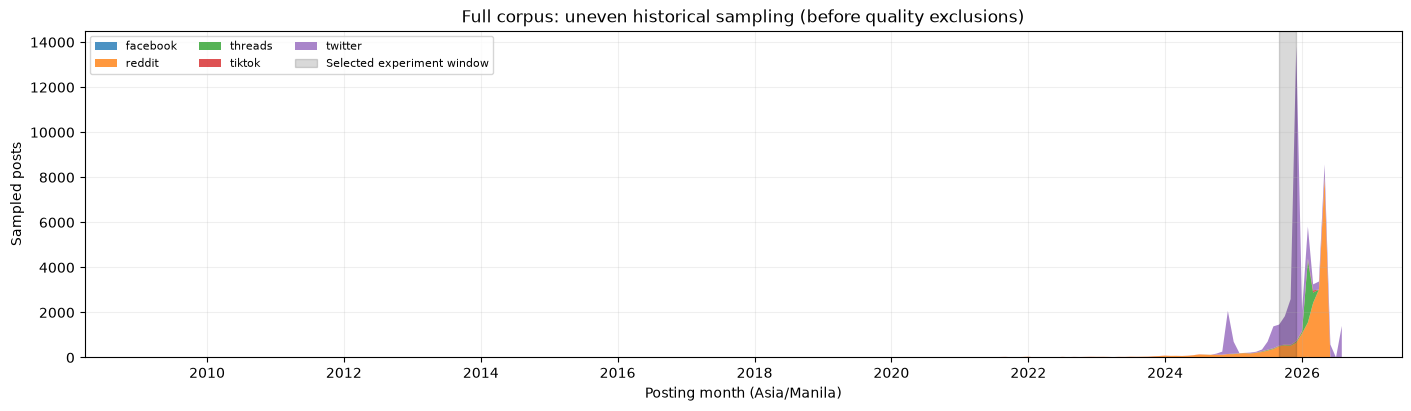

,eligible_posts
source,
facebook,11
reddit,1518
threads,65
tiktok,59
twitter,4215


In [2]:
CONFIG['dataset_sha256'] = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw_posts = pd.read_csv(DATA_PATH, usecols=['source', 'external_post_id', 'date_posted', 'cleaned_text'],
                        dtype=str, keep_default_na=False, encoding='utf-8-sig')
eligible_posts, exclusions, data_audit = prepare_posts(
    raw_posts, start_date=START_DATE, end_date=END_DATE, timezone=TIMEZONE)
write_json(REPORT_DIR / 'data_audit.json', data_audit)
save_table(exclusions, REPORT_DIR / 'exclusions')
write_json(REPORT_DIR / 'run_config.json', CONFIG)
print(json.dumps({key: data_audit[key] for key in
                  ('input_posts', 'selected_input_posts', 'duplicate_posts', 'selected_excluded_posts', 'eligible_posts')}, indent=2))
print('Selected-window exclusions:', data_audit['selected_exclusion_counts'])
print('Full-corpus exclusions (including outside-window posts):', data_audit['exclusion_counts'])
display(exclusions.head(10))

# Descriptive full-corpus counts include rows rejected later; they are not forecast targets.
audit_dates = pd.to_datetime(raw_posts['date_posted'], format='mixed', errors='coerce', utc=True)
audit_dates = audit_dates.dt.tz_convert(TIMEZONE).dt.tz_localize(None).dt.normalize()
full_monthly_sources = (raw_posts.assign(month=audit_dates.dt.to_period('M').dt.to_timestamp())
                        .dropna(subset=['month']).groupby(['month', 'source']).size()
                        .rename('sampled_post_count').reset_index())
save_table(full_monthly_sources, REPORT_DIR / 'full_corpus_monthly_sources')
monthly = full_monthly_sources.pivot(index='month', columns='source', values='sampled_post_count').fillna(0)
monthly = monthly.reindex(pd.date_range(monthly.index.min(), monthly.index.max(), freq='MS'), fill_value=0)
fig, ax = plt.subplots(figsize=(14, 4), layout='constrained')
ax.stackplot(monthly.index, monthly.to_numpy().T, labels=monthly.columns, alpha=0.8)
ax.axvspan(pd.Timestamp(START_DATE), pd.Timestamp(END_DATE) + pd.Timedelta(days=1),
           alpha=0.15, color='black', label='Selected experiment window')
ax.set(title='Full corpus: uneven historical sampling (before quality exclusions)',
       xlabel='Posting month (Asia/Manila)', ylabel='Sampled posts')
ax.legend(fontsize=8, ncol=3)
ax.grid(alpha=0.2)
save_figure(fig, REPORT_DIR / 'full_corpus_coverage')
display(eligible_posts.groupby('source').size().rename('eligible_posts').to_frame())


## 3. Attach frozen XLM-RoBERTa signals

The bundle is explicitly pinned to `full_20261022T064326Z_fa1cd053`; there is no automatic latest-model selection. Its AURI/PN/TB/COVID thresholds are 0.81/0.72/0.74/0.91. Each post may match several diseases or none. Scores are sigmoid text-classifier outputs, not calibrated clinical probabilities.

Inference runs locally on CPU, reusing one predictor. Cache entries are keyed by model version and normalized-text SHA-256 and retain thresholds and scores. Failed or incompatible results halt the run. Labeled-post exports contain durable IDs and results, excluding raw and cleaned text.

In [3]:
service_path = ROOT / 'xlmr-disease-detection-service'
if str(service_path) not in sys.path:
    sys.path.insert(0, str(service_path))
run_config_path = BUNDLE_DIR / 'run_config.json'
if not run_config_path.is_file():
    raise FileNotFoundError(f'Missing local XLM-RoBERTa bundle: {BUNDLE_DIR}')
model_run = json.loads(run_config_path.read_text(encoding='utf-8'))
if model_run.get('run_id') != EXPECTED_MODEL_RUN:
    raise ValueError('Bundle run does not match EXPECTED_MODEL_RUN. Select a complete bundle explicitly.')

os.environ['TOKENIZERS_PARALLELISM'] = 'false'
import torch
from healthph_xlmr import DiseasePredictor

torch.set_num_threads(CPU_THREADS)
predictor = DiseasePredictor(artifact_dir=BUNDLE_DIR)
CONFIG.update(model_run_id=model_run['run_id'], model_version=predictor.model_version,
              thresholds=predictor.thresholds, max_length=predictor.max_length)
write_json(REPORT_DIR / 'run_config.json', CONFIG)
print('Model run:', CONFIG['model_run_id'])
print('Model fingerprint:', CONFIG['model_version'])
print('Thresholds:', CONFIG['thresholds'])

started = time.perf_counter()
progress_state = {'last': -320}
def report_progress(completed, total):
    if completed == total or completed - progress_state['last'] >= 320:
        print(f'Label cache/inference: {completed}/{total} unique texts; '
              f'{time.perf_counter() - started:.1f}s elapsed', flush=True)
        progress_state['last'] = completed

labeled_posts = label_posts(eligible_posts, predictor, cache_path=CACHE_PATH,
                           batch_size=BATCH_SIZE, progress=report_progress)
CONFIG['labeling_seconds'] = time.perf_counter() - started
safe_columns = ['source', 'external_post_id', 'date', 'text_hash', 'model_version',
                *LABELS, *[f'probability_{label}' for label in LABELS]]
save_table(labeled_posts[safe_columns], REPORT_DIR / 'labeled_posts')
write_json(REPORT_DIR / 'run_config.json', CONFIG)
print(f'Labeled {len(labeled_posts):,} eligible posts. Successful predictions are cached.')
# Release model weights before plotting. Subsequent labeling cells can recreate the predictor.
del predictor
import gc
gc.collect()


/Users/gelo-p1/Documents/GitHub/HealthPH-Plus/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 21332.91it/s]

Model run: full_20261022T064326Z_fa1cd053
Model fingerprint: sha256:d770fc4d3ae7f8726bb8209bd39ed024da011968355398173d009a7803160f8b
Thresholds: {'AURI': 0.81, 'PN': 0.72, 'TB': 0.74, 'COVID': 0.91}
Label cache/inference: 5868/5868 unique texts; 0.0s elapsed


Labeled 5,868 eligible posts. Successful predictions are cached.


83

## 4. Build daily disease series

A count of zero means eligible sampled posts were analyzed but none matched that disease. A day with no eligible posts has an unavailable disease count, not zero. Forecast evaluation rejects missing days instead of filling them. Counts can sum above total eligible posts because disease labels are independent.

In [4]:
daily_series, daily_sources = aggregate_daily(
    labeled_posts, start_date=START_DATE, end_date=END_DATE, timezone=TIMEZONE)
save_table(daily_series, REPORT_DIR / 'daily_series')
save_table(daily_sources, REPORT_DIR / 'daily_sources')
print('Daily disease rows:', len(daily_series), '| unavailable:', daily_series['post_count'].isna().sum())
display(daily_series.pivot(index='date', columns='disease_label', values='post_count').head(10))
display(daily_series.groupby('disease_label').agg(
    total_disease_posts=('post_count', 'sum'), mean_daily_posts=('post_count', 'mean'),
    zero_count_days=('post_count', lambda values: int(values.eq(0).sum()))))


Daily disease rows: 364 | unavailable: 0


disease_label,AURI,COVID,PN,TB
date,,,,
2025-09-01,4,4,4,4
2025-09-02,5,5,5,5
2025-09-03,7,7,7,7
2025-09-04,6,5,5,5
2025-09-05,5,4,4,4
2025-09-06,3,3,3,3
2025-09-07,5,5,5,5
2025-09-08,4,4,4,4
2025-09-09,3,3,3,3


,total_disease_posts,mean_daily_posts,zero_count_days
disease_label,,,
AURI,831,9.131868,0
COVID,799,8.78022,1
PN,802,8.813187,1
TB,798,8.769231,1


## 5. Expanding weekly evaluation

Baselines: **zero**, **last observed count**, **repeat the previous seven days**, and **repeat the mean of the previous seven days**. No within-week forecast can use that week's actual values. At the next weekly origin, already observed actuals become available.

Default splits:

| Stage | Target dates | Origins |
|---|---|---|
| Initial history | September 1–October 26, 2025 | 56 days |
| Validation | October 27–November 16, 2025 | 3 × 7 days |
| Test | November 17–30, 2025 | 2 × 7 days |

Choose one baseline per disease using validation MAE, then RMSE, then the baseline order above. Freeze choices before evaluating test predictions. MAE and RMSE are reported in posts, including zero-count days; no percentage-error metric is used.

See [scikit-learn's chronological validation guidance](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html) for why time order must be preserved.

In [5]:
evaluation = evaluate_baselines(
    daily_series, initial_train_days=INITIAL_TRAIN_DAYS,
    validation_folds=VALIDATION_FOLDS, test_folds=TEST_FOLDS, horizon=HORIZON)
display(evaluation['folds'])
display(evaluation['selected_models'])
selected_test_metrics = evaluation['metrics'].loc[
    evaluation['metrics']['split'].eq('test') & evaluation['metrics']['is_selected']]
save_table(selected_test_metrics, REPORT_DIR / 'selected_test_metrics')
print('Held-out test performance for validation-selected models:')
display(selected_test_metrics)
print('Per-horizon metrics (all diseases/models exported):')
display(evaluation['horizon_metrics'].loc[
    evaluation['horizon_metrics']['split'].eq('test') & evaluation['horizon_metrics']['is_selected']])


,split,fold,origin_date,train_start,train_end,target_start,target_end,train_days,target_days
0,validation,1,2025-10-26,2025-09-01,2025-10-26,2025-10-27,2025-11-02,56,7
1,validation,2,2025-11-02,2025-09-01,2025-11-02,2025-11-03,2025-11-09,63,7
2,validation,3,2025-11-09,2025-09-01,2025-11-09,2025-11-10,2025-11-16,70,7
3,test,1,2025-11-16,2025-09-01,2025-11-16,2025-11-17,2025-11-23,77,7
4,test,2,2025-11-23,2025-09-01,2025-11-23,2025-11-24,2025-11-30,84,7
5,demonstration,1,2025-11-30,2025-09-01,2025-11-30,2025-12-01,2025-12-07,91,7


,disease_label,model,validation_mae,validation_rmse
0,AURI,last_value,2.238095,2.853569
1,PN,last_value,2.000000,2.581989
2,TB,last_value,2.000000,2.581989
3,COVID,last_value,2.285714,2.911390


Held-out test performance for validation-selected models:


,split,disease_label,model,mae,rmse,n,is_selected
17,test,AURI,last_value,36.714286,44.152334,14,True
21,test,PN,last_value,36.785714,44.161231,14,True
25,test,TB,last_value,36.928571,44.338793,14,True
29,test,COVID,last_value,37.000000,44.342820,14,True


Per-horizon metrics (all diseases/models exported):


,split,disease_label,model,horizon,mae,rmse,n,is_selected
119,test,AURI,last_value,1,20.0,27.586228,2,True
120,test,AURI,last_value,2,24.0,32.557641,2,True
121,test,AURI,last_value,3,27.5,38.890873,2,True
122,test,AURI,last_value,4,56.5,56.555283,2,True
123,test,AURI,last_value,5,41.0,45.617979,2,True
124,test,AURI,last_value,6,28.5,38.242646,2,True
125,test,AURI,last_value,7,59.5,59.753661,2,True
147,test,PN,last_value,1,21.0,28.319605,2,True
148,test,PN,last_value,2,24.5,33.264095,2,True
149,test,PN,last_value,3,27.5,38.890873,2,True


## 6. Reports and retrospective demonstration

Charts combine source composition, disease trends, baseline errors, horizon errors, and historical forecast overlays. Tables preserve individual origins and actuals so aggregate errors can be checked.

The demonstration forecasts the seven days following the configured window: **December 1–7, 2025** by default. It does not use later posts in forecasts or score against later disease counts. These dates are historical and are not a forecast for today's surveillance conditions. Fractional forecasts represent expected counts; they are retained without rounding.

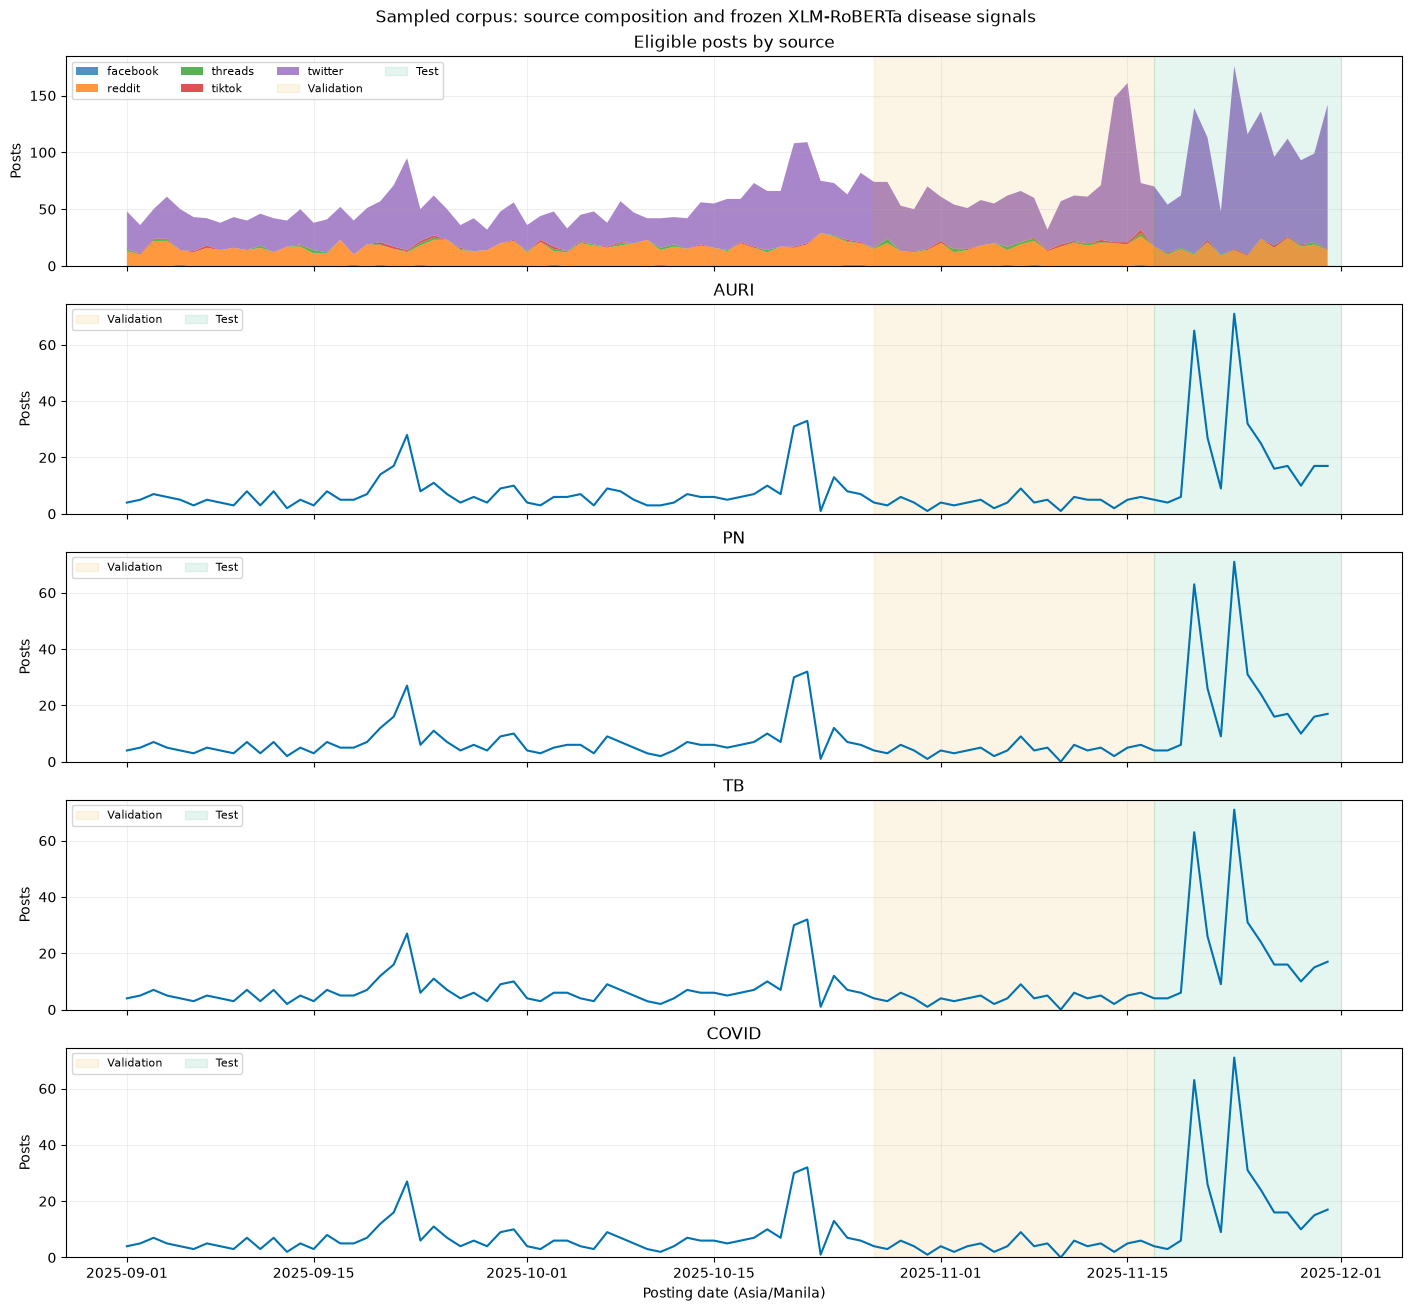

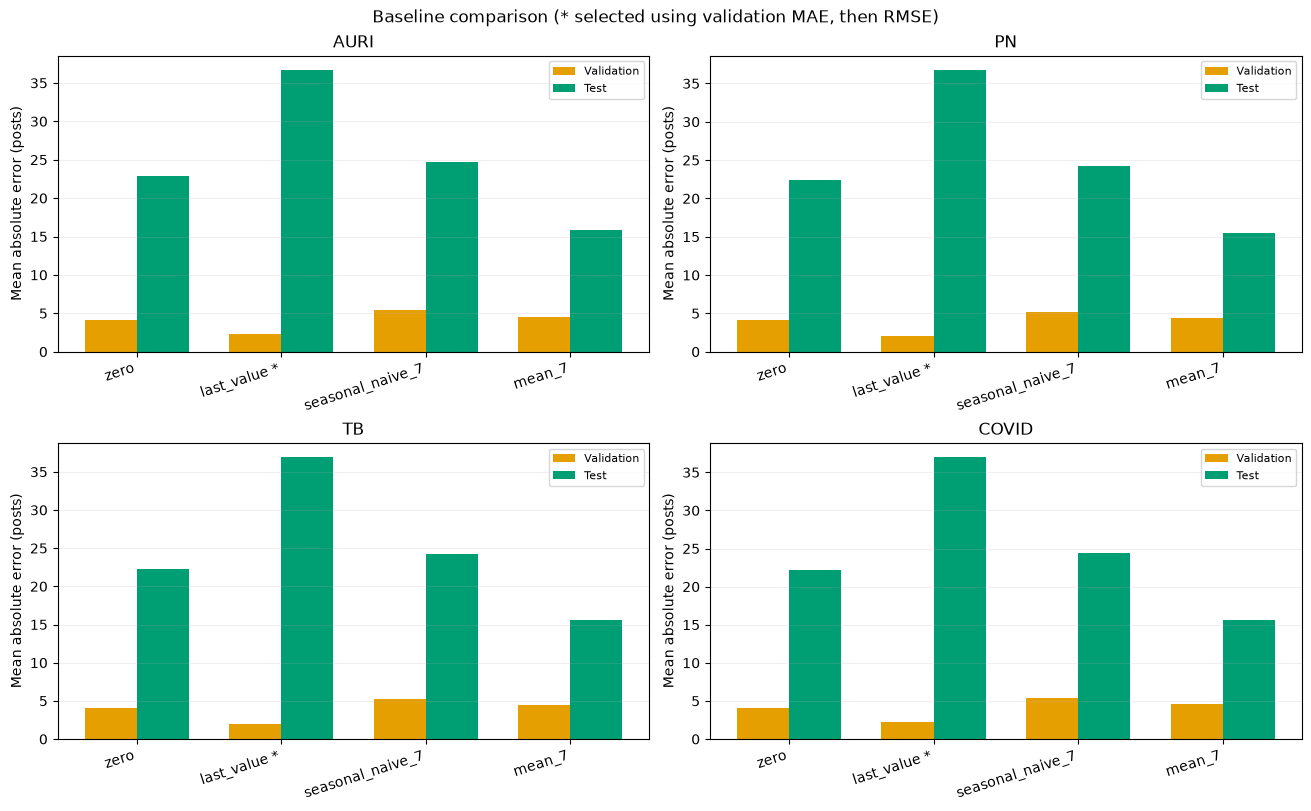

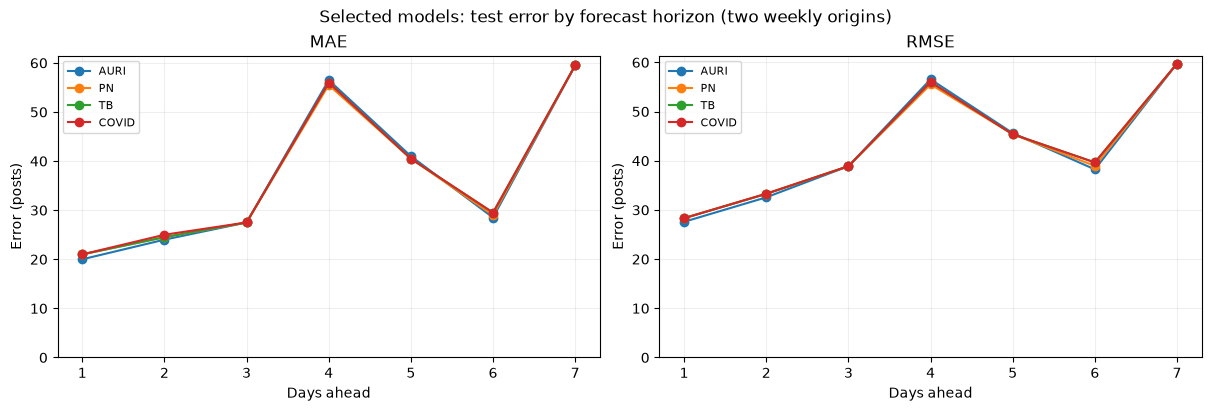

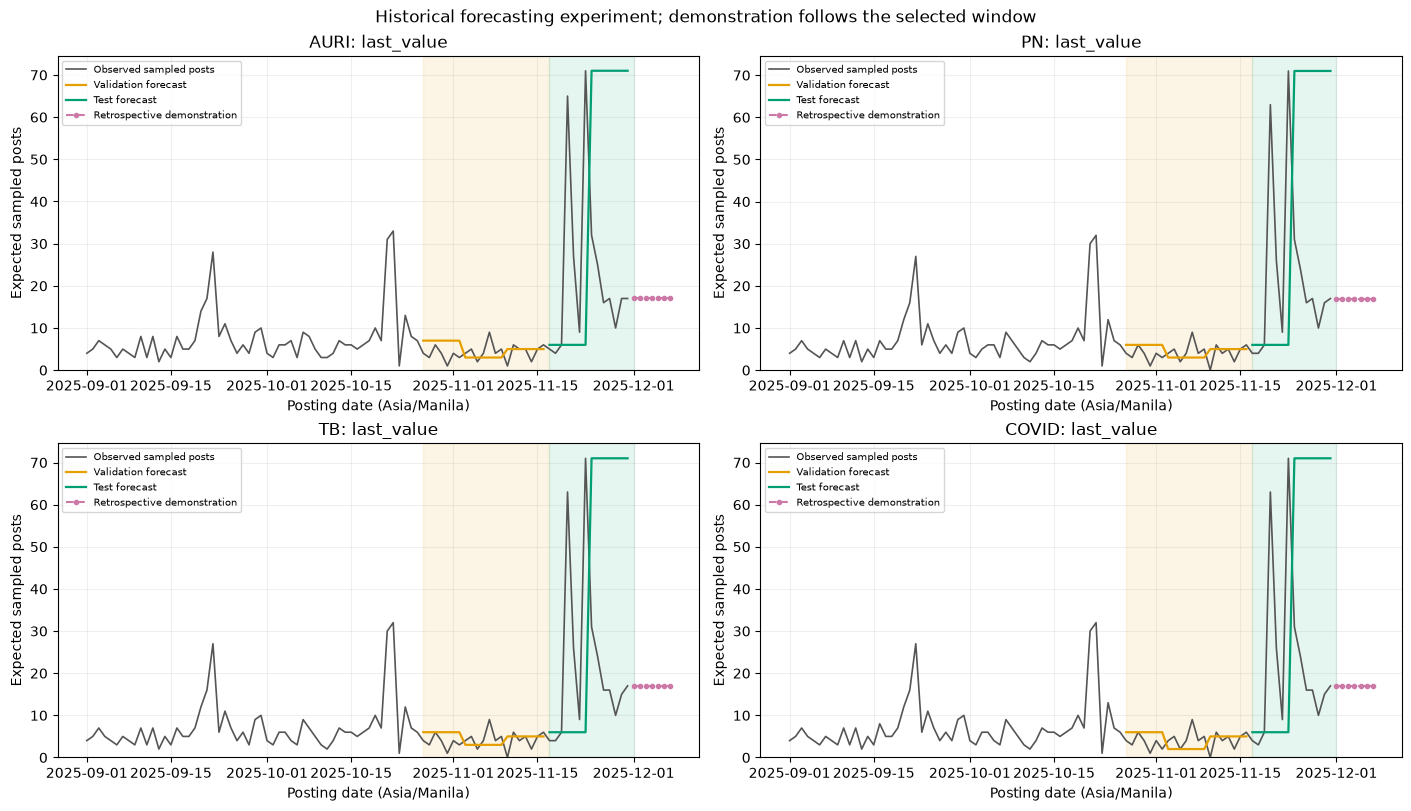

disease_label,AURI,COVID,PN,TB
target_date,,,,
2025-12-01,17.0,17.0,17.0,17.0
2025-12-02,17.0,17.0,17.0,17.0
2025-12-03,17.0,17.0,17.0,17.0
2025-12-04,17.0,17.0,17.0,17.0
2025-12-05,17.0,17.0,17.0,17.0
2025-12-06,17.0,17.0,17.0,17.0
2025-12-07,17.0,17.0,17.0,17.0


Complete: /Users/gelo-p1/Documents/GitHub/HealthPH-Plus/reports/forecasting/20261028T062743Z_7ad49ebb
Verified 34 table/figure artifacts plus configuration, audit, and manifest.


In [6]:
artifacts = export_forecast_report(daily_series, daily_sources, evaluation, REPORT_DIR, show=True)
display(evaluation['forecast'].pivot(index='target_date', columns='disease_label', values='prediction'))

# Verify the complete run's artifact contract before marking it complete.
table_names = ['exclusions', 'labeled_posts', 'full_corpus_monthly_sources',
               'daily_series', 'daily_sources', 'predictions', 'metrics',
               'horizon_metrics', 'selected_models', 'forecast', 'folds', 'selected_test_metrics']
figure_names = ['full_corpus_coverage', 'daily_counts_and_sources', 'baseline_comparison',
                'horizon_errors', 'retrospective_forecasts']
expected_paths = [REPORT_DIR / (name + suffix) for name in table_names for suffix in ('.csv', '.json')]
expected_paths += [REPORT_DIR / (name + suffix) for name in figure_names for suffix in ('.png', '.svg')]
missing = [str(path) for path in expected_paths if not path.is_file() or path.stat().st_size == 0]
if missing:
    raise RuntimeError(f'Missing/empty report artifacts: {missing}')
if len(evaluation['forecast']) != len(LABELS) * HORIZON or evaluation['forecast']['actual'].notna().any():
    raise RuntimeError('The demonstration must contain seven unknown-actual forecasts per disease.')
CONFIG['status'] = 'complete'
CONFIG['completed_at_utc'] = datetime.now(timezone.utc).isoformat()
write_json(REPORT_DIR / 'run_config.json', CONFIG)
write_json(REPORT_DIR / 'artifact_manifest.json', [
    {'path': path.name, 'bytes': path.stat().st_size,
     'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
    for path in sorted([*expected_paths, REPORT_DIR / 'run_config.json', REPORT_DIR / 'data_audit.json'])])
print('Complete:', REPORT_DIR)
print(f'Verified {len(expected_paths)} table/figure artifacts plus configuration, audit, and manifest.')


## Interpretation and next milestone

Use held-out errors as a baseline for this fixed sampled corpus. Review source changes alongside disease counts before attributing a rise to illness. The frozen classifier can make labeling errors, and its post-period training means this reconstruction cannot establish a prospective benefit.

The next milestone can compare advanced forecasting models after this baseline is established. Consistent collection coverage, official case-count targets, sentiment predictors, and backend integration require separate data and evaluation decisions.

### Initial completed experiment

The executed default run `20261028T062021Z_d7e683bf` used 5,868 eligible posts. Its validation-selected results are recorded in the [exported metrics](../reports/forecasting/20261028T062021Z_d7e683bf/metrics.csv). Errors below are in posts per day.

| Disease | Selected baseline | Validation MAE | Test MAE | Test RMSE |
|---|---|---:|---:|---:|
| AURI | `last_value` | 2.24 | 36.71 | 44.15 |
| PN | `last_value` | 2.00 | 36.79 | 44.16 |
| TB | `last_value` | 2.00 | 36.93 | 44.34 |
| COVID | `last_value` | 2.29 | 37.00 | 44.34 |

Of 831 disease-positive posts, 795 received all four labels. This high co-occurrence makes the disease series nearly identical and warrants classifier review. The validation-to-test error increase also shows that these baselines transfer poorly across this sampled period; do not treat the demonstration as an operational surveillance forecast.